In [1]:
# Import Packages
using Logging: global_logger
using TerminalLoggers: TerminalLogger
global_logger(TerminalLogger())

using ProgressLogging

using LinearAlgebra
using Random
using Statistics
using Plots
using LaTeXStrings
using Revise
using StaticArrays
using Interpolations
using LazySets
using SpatiotemporalGPs

In [2]:
# setup the spatial and temporal kernels
σt = 2.0   # m/s
σs = 1.0   # m/s
lt = 3*60.0  # minutes
ls = 3.0   # km

kt = Matern(3/2, σt, lt)
ks = Matern(1/2, σs, ls)

# determine the temporal step size
Δt = 5.0 # minutes
Δx = 0.25 # km

# create the spatial domain
xs = 0:Δx:7.0
ys = 0:Δx:10.0

grid_pts = vec([@SVector[x, y] for x in xs, y in ys]);

# Synthetic Data

In [3]:
# let us generate the synthetic data first
tmax = 4 * 60.0 # minutes
synthetic_data = STGPKF.generate_spatiotemporal_process(xs, ys, Δt, tmax, ks, kt);

[ Info: Saved animation to /tmp/jl_TurApQXyXI.gif


Plots.AnimatedGif("/tmp/jl_TurApQXyXI.gif")
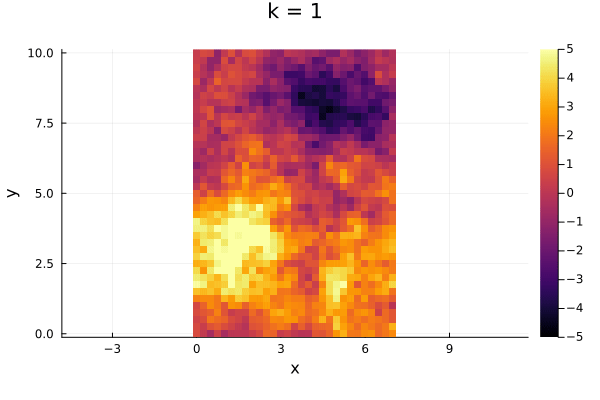

In [4]:
# visualize the ground truth data
@gif for k=1:length(synthetic_data.ts)
    heatmap(synthetic_data.xs, synthetic_data.ys, synthetic_data.data[:, :, k]', clims=(-5,5))
    title!("k = $k")
    xlabel!("x")
    ylabel!("y")
    plot!(aspect_ratio=:equal)
end

# STGPKF Update/Estimation

In [5]:
problem = STGPKFProblem(grid_pts, ks, kt, Δt)

STGPKFProblem{SVector{2, Float64}, Float64, Vector{SVector{2, Float64}}, SpatiotemporalGPs.STGPKF.Matern12{Float64}, SpatiotemporalGPs.STGPKF.Matern32{Float64}, SpatiotemporalGPs.STGPKF.DiscreteTimeStateSpaceModel{SMatrix{2, 2, Float64, 4}, SMatrix{2, 2, Float64, 4}, SMatrix{1, 2, Float64, 2}, Float64}, Symmetric{Float64, Matrix{Float64}}, Symmetric{Float64, Matrix{Float64}}}(SVector{2, Float64}[[0.0, 0.0], [0.25, 0.0], [0.5, 0.0], [0.75, 0.0], [1.0, 0.0], [1.25, 0.0], [1.5, 0.0], [1.75, 0.0], [2.0, 0.0], [2.25, 0.0]  …  [4.75, 10.0], [5.0, 10.0], [5.25, 10.0], [5.5, 10.0], [5.75, 10.0], [6.0, 10.0], [6.25, 10.0], [6.5, 10.0], [6.75, 10.0], [7.0, 10.0]], SpatiotemporalGPs.STGPKF.Matern12{Float64}(1.0, 0.3333333333333333), SpatiotemporalGPs.STGPKF.Matern32{Float64}(4.0, 0.005555555555555556), 5.0, SpatiotemporalGPs.STGPKF.DiscreteTimeStateSpaceModel{SMatrix{2, 2, Float64, 4}, SMatrix{2, 2, Float64, 4}, SMatrix{1, 2, Float64, 2}, Float64}([0.9988790551645961 4.7651327208952186; -0.000441

In [6]:
# construct the state at time 0 conditioned on no measurements
state_initial = stgpkf_initialize(problem) 

KFState{Float64, Vector{Float64}, Matrix{Float64}}([0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0  …  0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [529.7095721488881 0.0 … 0.0 0.0; 0.0 5.0971327345413675 … 0.0 0.0; … ; 0.0 0.0 … 529.7095721488881 0.0; 0.0 0.0 … 0.0 5.0971327345413675])

In [7]:
# do some measurements

function rand_point(xs, ys)
    xmin, xmax = extrema(xs)
    ymin, ymax = extrema(ys)
    x = (xmax - xmin) * rand() + xmin
    y = (ymax - ymin) * rand() + ymin
    return @SVector [x, y]
end

function measure(data, x, y, t, σ_m=0.1)
    return data.itp(x, y, t) + σ_m *randn()
end

measure_pt = rand_point(xs, ys)
measure_σ = 0.1 # m/s
measure_y = measure(synthetic_data, measure_pt..., synthetic_data.ts[1], measure_σ)

-0.29179657578419854

In [8]:
# do the correction

state_1_1 = stgpkf_correct(problem, state_initial, measure_pt, measure_y, measure_σ)

KFState{Float64, Vector{Float64}, Matrix{Float64}}([-0.15107525792025808, 0.0, -0.14701446657783837, 0.0, -0.14279271704144544, 0.0, -0.1385321379367251, 0.0, -0.13428394331130342, 0.0  …  -0.4053560496876037, 0.0, -0.36624094323995215, 0.0, -0.3312671853107287, 0.0, -0.2999418571661278, 0.0, -0.27181252337019773, 0.0], [-529.7085781716465 0.0 … 0.0035767036825777488 0.0; 0.0 5.0971327345413675 … 0.0 0.0; … ; 0.0 0.0 … -529.3700641580872 0.0; 0.0 0.0 … 0.0 5.0971327345413675])

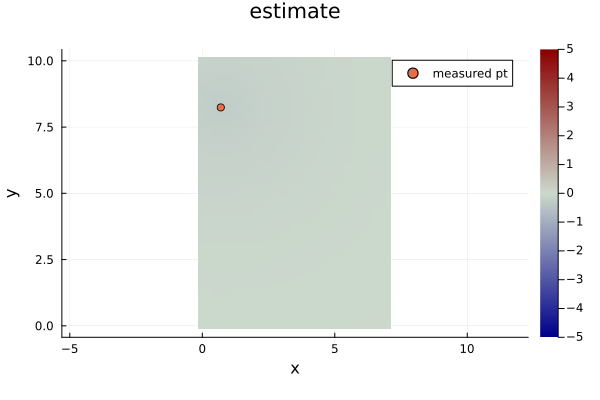

In [9]:
plot(problem, state_1_1; plot_type=:estimate, clims=(-5, 5), cmap=:bluesreds, aspect_ratio=:equal)
scatter!([measure_pt[1]], [measure_pt[2]], label="measured pt")

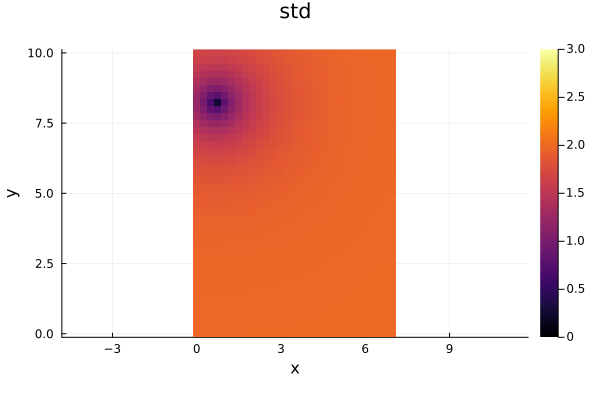

In [10]:
plot(problem, state_1_1; plot_type=:std, clims=(0, 3), aspect_ratio=:equal)

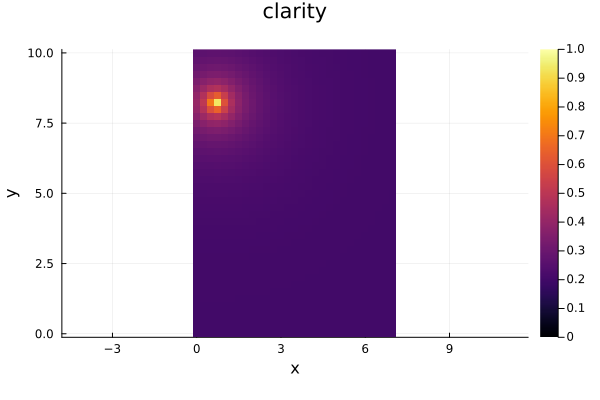

In [11]:
plot(problem, state_1_1; plot_type=:clarity, clims=(0, 1), aspect_ratio=:equal)

# Simulation

In [12]:


# construct the state at time 0 conditioned on no measurements
state = stgpkf_initialize(problem) 

states = (typeof(state))[]

for k=1:length(synthetic_data.ts)

    # @show k

    # make some measurements
    measure_pts = [rand_point(xs, ys) for i=1:10]
    measure_ys = [measure(synthetic_data, pt..., synthetic_data.ts[k], measure_σ) for pt in measure_pts]
    measure_Σ = (measure_σ^2) * I(10);

    if k == length(synthetic_data.ts)
        println("measure_pts: ", measure_pts)
        println("measure_ys: ", measure_ys)
        println("measure_Σ: ", measure_Σ)
    end


    # do the KF correction
    state_correction = stgpkf_correct(problem, state, measure_pts, measure_ys, measure_Σ)

    # add it to the states
    push!(states, state_correction)

    # do a prediction
    state = stgpkf_predict(problem, state_correction)

end
 

measure_pts: SVector{2, Float64}[[1.355937231295643, 5.60777414846104], [3.3821794512961687, 5.107162505725903], [5.717862627564339, 3.9045890914968737], [5.262124937156819, 7.042337177263737], [3.7263902550529453, 8.061010236070112], [4.417892141223532, 9.148009986606747], [2.61824481801023, 2.2091349907155555], [5.91322798292342, 6.433158972468388], [3.9292334805956193, 1.3796107425219906], [1.0803425712398314, 8.16890618611512]]
measure_ys: [0.2402395832628066, -1.7723395313252837, 1.1400687068824127, -2.1866581413720305, -1.587222458069729, -2.060996195978721, -0.6826597747446882, 0.19885710298002626, -1.2916808021828277, -1.133337455112093]
measure_Σ: [0.010000000000000002 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.010000000000000002 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.010000000000000002 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.010000000000000002 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.010000000000000002 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.010000000000000002 0.0

In [13]:
    

states
     


48-element Vector{KFState{Float64, Vector{Float64}, Matrix{Float64}}}:
 KFState{Float64, Vector{Float64}, Matrix{Float64}}([26.96053096850598, 0.0, 26.332216536206516, 0.0, 25.6148711595702, 0.0, 24.862690591221707, 0.0, 24.093607160896447, 0.0  …  -5.287576137102651, 0.0, -4.384113062725568, 0.0, -3.457563640264767, 0.0, -2.5196242063426633, 0.0, -1.5830698504103404, 0.0], [-529.581730154154 0.0 … -0.0009619473284742877 0.0; 0.0 5.0971327345413675 … 0.0 0.0; … ; 0.0 0.0 … -521.7007275807705 0.0; 0.0 0.0 … 0.0 5.0971327345413675])
 KFState{Float64, Vector{Float64}, Matrix{Float64}}([22.38337715333406, 0.002503642696497223, 19.633498487404445, 0.0025965652818187666, 15.716549056154008, 0.002705521691427522, 10.431047885867727, 0.0028375240447809976, 3.516995549203642, 0.0029997689242210294  …  -24.96669217746757, -0.001850455035272276, -24.742855633357827, -0.0022438453782142984, -24.279901871455674, -0.002644143039303164, -23.567164421823076, -0.0030509080972420744, -22.587289187238532

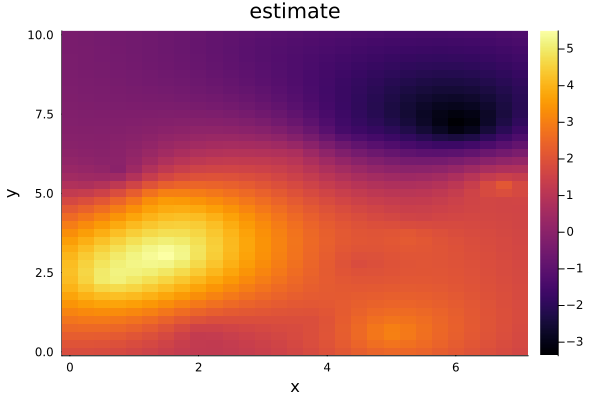

In [14]:
plot(problem, states[2])

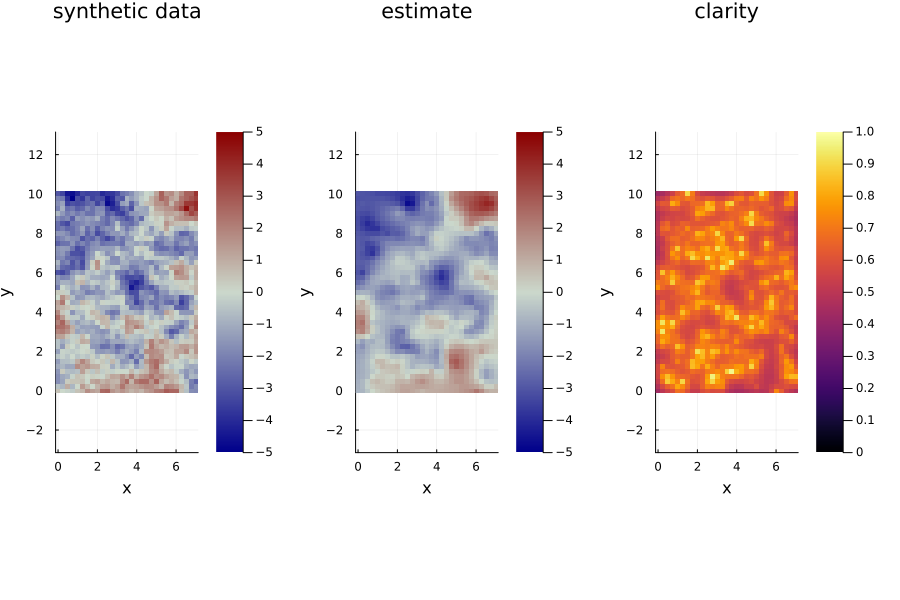

In [15]:

k = 40

p0 = plot(synthetic_data, synthetic_data.ts[k]; clims=(-5, 5), cmap = :bluesreds, aspect_ratio=:equal)
title!("synthetic data")
p1 = plot(problem, states[k]; plot_type=:estimate, clims=(-5, 5), cmap=:bluesreds, aspect_ratio=:equal)
p2 = plot(problem, states[k]; plot_type=:clarity, clims=(0, 1), aspect_ratio=:equal)
plot(p0, p1, p2, layout=(@layout [a b c]), size=(900, 600))
     


[ Info: Saved animation to /tmp/jl_VAdkHKLGfs.gif


Plots.AnimatedGif("/tmp/jl_VAdkHKLGfs.gif")
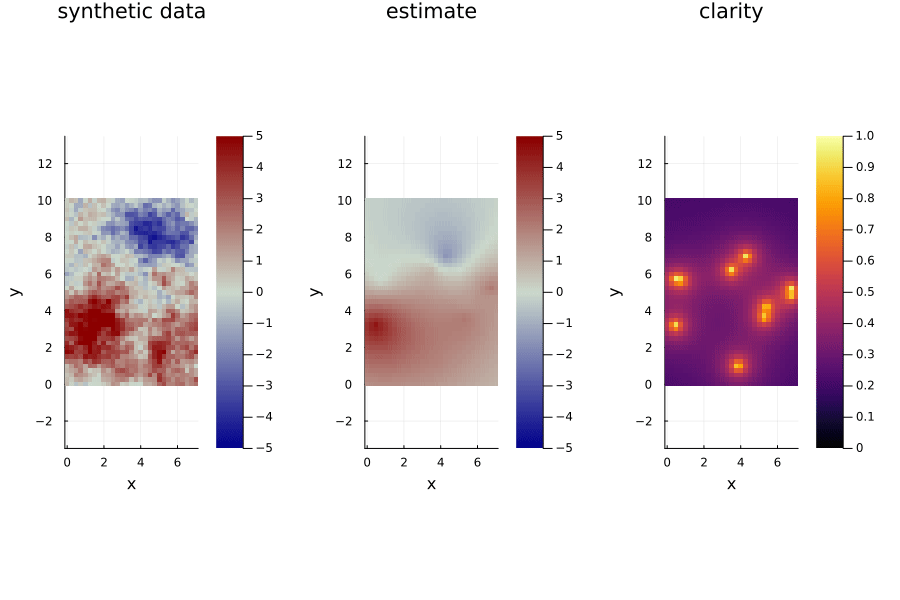

In [16]:

@gif for k=1:length(states)
    p0 = plot(synthetic_data, synthetic_data.ts[k]; clims=(-5, 5), cmap = :bluesreds, aspect_ratio=:equal)
    title!("synthetic data")
    p1 = plot(problem, states[k]; plot_type=:estimate, clims=(-5, 5), cmap=:bluesreds, aspect_ratio=:equal)
    p2 = plot(problem, states[k]; plot_type=:clarity, clims=(0, 1), aspect_ratio=:equal)
    plot(p0, p1, p2, layout=(@layout [a b c]), size=(900, 600))
end
     


[ Info: Saved animation to /tmp/jl_90tq5cLkZ0.gif


Plots.AnimatedGif("/tmp/jl_90tq5cLkZ0.gif")
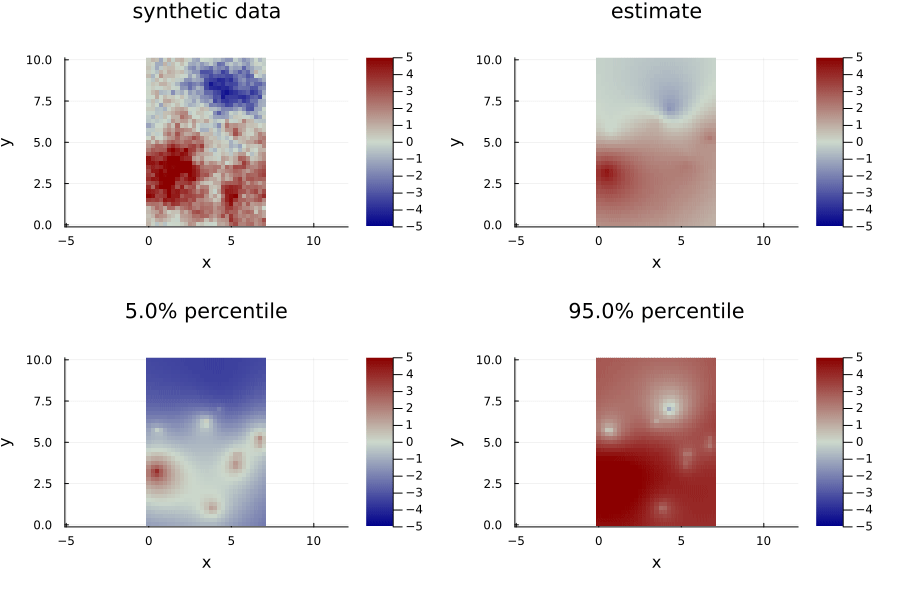

In [17]:

@gif for k=1:length(states)
    p0 = plot(synthetic_data, synthetic_data.ts[k]; clims=(-5, 5), cmap = :bluesreds, aspect_ratio=:equal)
    title!("synthetic data")
    p1 = plot(problem, states[k]; plot_type=:estimate, clims=(-5, 5), cmap=:bluesreds, aspect_ratio=:equal)
    
    p2 = plot(problem, states[k]; plot_type=:percentile, percentile=0.05, clims=(-5, 5), cmap=:bluesreds, aspect_ratio=:equal)

    p3 = plot(problem, states[k]; plot_type=:percentile, percentile=0.95, clims=(-5, 5), cmap=:bluesreds, aspect_ratio=:equal)
    
    plot(p0, p1, p2, p3, layout=(@layout [a b; c d]), size=(900, 600))
end
     


In [18]:

# check if the data is within the estimate
     


tol = 0.1

fs = Float64[]
for k=1:length(states)
    M_05 = STGPKF.get_estimate_percentile(problem, states[k], tol/2)
    M_95 = STGPKF.get_estimate_percentile(problem, states[k], (1 - tol/2))
    M_true = vec(synthetic_data.data[:,:, k])
    f = sum(M_05 .<= M_true .<= M_95) / length(M_true)
    push!(fs, f)
end
     



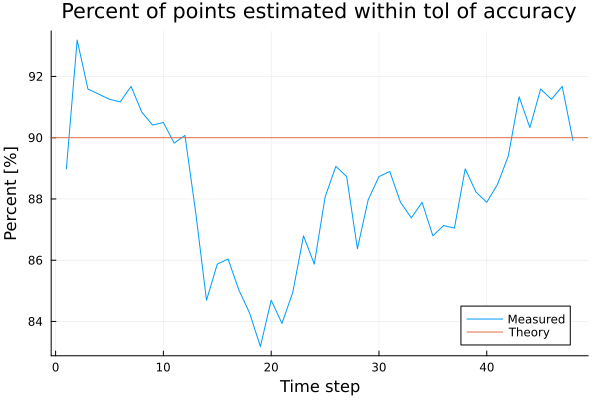

In [19]:

     

plot(100*fs, label="Measured")
hline!([100*(1 - tol)], label="Theory")
xlabel!("Time step")
title!("Percent of points estimated within tol of accuracy")
ylabel!("Percent [%]")
     
